# D2.2 · Forecast daily ATM cash

**PowerPoint slides** 15–19  
**Course data** atm_cash_daily.csv

### The problem

How much cash might customers withdraw from one ATM over the next two weeks?

### What this demo shows

Read the ATM’s daily amounts, look back at earlier days, and compare two simple ways of guessing the next 14 days. A forecast is a guess about the future.

### Why we’re doing it

People making a cash plan only have information up to the day they make the plan. Checking a forecast the same way makes the exercise realistic.

**If this is your first ML activity**, open [00 · Your first ML workflow](00_Start_Here_Your_First_ML_Workflow.ipynb) first. For the simpler examples of model types and repeated checking, see [01 · Regression and classification](01_Regression_and_Classification.ipynb) and [03 · K-fold cross-validation](03_K_Fold_Cross_Validation.ipynb).

Here, read the plain-English explanation before each cell. Run **Setup**, then work down the page with **Shift + Enter**.

## Setup · Load the data

Use ATM100’s longer history for the calendar discussion and July–October 2025 for the short examples. The first few lines locate the course data folder. You can
run the whole cell as written.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.model_selection import TimeSeriesSplit

working_folder = Path.cwd()
data_folder = next(
    (folder / 'data' for folder in (working_folder, *working_folder.parents)
     if (folder / 'data' / 'property_valuations.csv').is_file()),
    None,
)
if data_folder is None:
    raise FileNotFoundError('Open the extracted course folder in Jupyter or VS Code.')

columns = ["date", "atm_id", "withdrawal_aed", "is_weekend", "weekend_regime", "is_payday_window"]
cash = pd.read_csv(data_folder / "atm_cash_daily.csv", usecols=columns, parse_dates=["date"])
atm = cash[cash["atm_id"] == "ATM100"].sort_values("date").set_index("date")
recent = atm.loc["2025-07-01":].copy()
display(recent.head(3))

,atm_id,withdrawal_aed,is_payday_window,weekend_regime,is_weekend
date,,,,,
2025-07-01,ATM100,62400.0,1,Sat-Sun,0
2025-07-02,ATM100,57700.0,1,Sat-Sun,0
2025-07-03,ATM100,53600.0,0,Sat-Sun,0


## 1 · Follow the line through time

**What we’re doing.** Draw daily cash withdrawals as a line and add another line that averages 30 days.

**Why we’re doing it.** There is a lot of day-to-day movement. Averaging helps us see slower changes that can affect future cash needs.

**What to look for.** Follow the smoother line and zoom in mentally on the daily movement. A steady trend or repeating weekly pattern can affect a forecast.

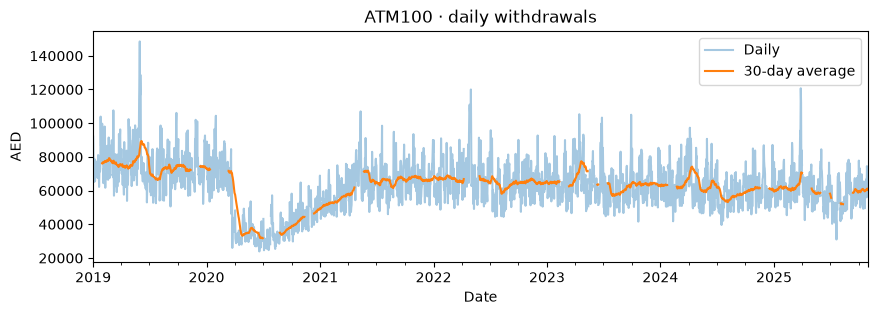

In [2]:
withdrawals = atm["withdrawal_aed"]
ax = withdrawals.plot(figsize=(10, 3), alpha=0.4, label="Daily")
withdrawals.rolling(30).mean().plot(ax=ax, label="30-day average")
ax.set(title="ATM100 · daily withdrawals", xlabel="Date", ylabel="AED")
ax.legend()
plt.show()

## 2 · See a calendar change

**What we’re doing.** Look at the calendar rows around January 2022 and group recent amounts by weekday.

**Why we’re doing it.** A forecast based on old weekends can get the pattern wrong if the days counted as weekends have changed.

**What to look for.** January 2 is flagged as a weekend. Compare the weekday averages as a quick calendar profile.

In [3]:
display(atm.loc["2021-12-31":"2022-01-03", ["weekend_regime", "is_weekend"]])
weekday = recent.index.day_name()
display(recent.groupby(weekday)["withdrawal_aed"].mean().round(0).rename("Average AED"))

,weekend_regime,is_weekend
date,,
2021-12-31,Fri-Sat,1
2022-01-01,Sat-Sun,1
2022-01-02,Sat-Sun,1
2022-01-03,Sat-Sun,0


date
Friday       62944.0
Monday       53941.0
Saturday     59138.0
Sunday       52218.0
Thursday     57222.0
Tuesday      59859.0
Wednesday    55841.0
Name: Average AED, dtype: float64

## 3 · Compare today with an earlier day

**What we’re doing.** Compare a day’s cash amount with the amounts one and seven days earlier.

**Why we’re doing it.** Earlier amounts are clues we already have. Comparing how closely they move helps us decide which clues to try.

**What to look for.** There are three missing readings. The correlations are about 0.52 and 0.23 in this window.

In [4]:
actual = recent["withdrawal_aed"]
observed_series = actual.ffill()
print("Missing readings:", actual.isna().sum())
print("Correlation with yesterday:", round(observed_series.autocorr(1), 2))
print("Correlation with seven days ago:", round(observed_series.autocorr(7), 2))

Missing readings: 3
Correlation with yesterday: 0.52
Correlation with seven days ago: 0.23


## 4 · Build features that were known

**What we’re doing.** Show which columns contain cash amounts from at least seven days earlier.

**Why we’re doing it.** Someone making a seven-day forecast will only have the older readings. Keeping the dates visible helps us spot an input that gives away the answer.

**What to look for.** The fourth column averages older days. For each row, locate the seven-day lag before discussing the average.

In [5]:
preview = pd.DataFrame({
    "Today (answer)": actual,
    "Includes today": observed_series.rolling(7).mean(),
    "7 days ago": observed_series.shift(7),
    "Past average": observed_series.shift(7).rolling(7).mean(),
})
display(preview.iloc[14:18].round(0))

,Today (answer),Includes today,7 days ago,Past average
date,,,,
2025-07-15,41100.0,49243.0,50300.0,53129.0
2025-07-16,42500.0,48571.0,47200.0,51629.0
2025-07-17,50400.0,48143.0,53400.0,51600.0
2025-07-18,52800.0,48100.0,53100.0,51529.0


## 5 · Compare two 14-day forecasts

**What we’re doing.** Try two simple guesses for the same 14 days. Repeat the last known amount or repeat last week’s amounts.

**Why we’re doing it.** We can choose between them by seeing which misses by less on these days. Using the same dates makes the comparison fair.

**What to look for.** On these validation dates, repeating the last week gives the smaller error, about AED 9,379.

In [6]:
history = actual.iloc[:-28].ffill()
validation = actual.iloc[-28:-14].dropna()
calendar_dates = actual.index[-28:-14]
last_value = pd.Series(history.iloc[-1], index=calendar_dates)
last_week = pd.Series(history.tail(7).tolist() * 2, index=calendar_dates)
candidates = pd.DataFrame({"Actual": validation, "Repeat last value": last_value, "Repeat last week": last_week})
display(candidates.head(4))
mae = candidates[["Repeat last value", "Repeat last week"]].sub(validation, axis=0).abs().mean()
display(mae.round(0).rename("Validation MAE in AED"))

,Actual,Repeat last value,Repeat last week
date,,,
2025-10-04,64900.0,73400.0,63900.0
2025-10-05,50300.0,73400.0,54800.0
2025-10-06,50000.0,73400.0,68700.0
2025-10-07,56700.0,73400.0,63400.0


Repeat last value    15436.0
Repeat last week      9379.0
Name: Validation MAE in AED, dtype: float64

## 6 · Check the selected forecast on later days

**What we’re doing.** Check the chosen guess on the final 14 days and show the misses in AED and percentages.

**Why we’re doing it.** A cash planner can understand the AED miss directly. Percentages put the miss in context compared with the cash withdrawn.

**What to look for.** The final MAE is about AED 7,357. The percentage metrics use different denominators.

In [7]:
test = actual.tail(14)
previous_week = actual.iloc[:-14].ffill().tail(7)
prediction = pd.Series(previous_week.tolist() * 2, index=test.index)
error = (test - prediction).abs()
print(f"MAE: AED {error.mean():,.0f}")
print(f"MAPE: {(error / test.where(test > 0)).mean():.1%}")
print(f"WAPE: {error.sum() / test.sum():.1%}")

MAE: AED 7,357
MAPE: 11.8%
WAPE: 11.9%


### See how a repeated week compares with actual withdrawals

The dashed line repeats its weekly pattern. The vertical space between the two lines shows the miss on each date.

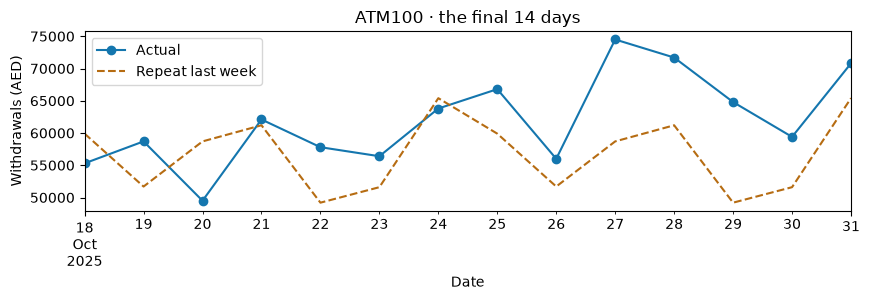

In [8]:
check = pd.DataFrame({"Actual": test, "Repeat last week": prediction})
ax = check["Actual"].plot(figsize=(8.8, 3.1), marker="o", color="#1476ae")
check["Repeat last week"].plot(ax=ax, linestyle="--", color="#b66c12")
ax.set(title="ATM100 · the final 14 days", xlabel="Date", ylabel="Withdrawals (AED)")
ax.legend()
plt.tight_layout()
plt.show()

## 7 · Move the origin forward

**What we’re doing.** Move the last day we know forward and show the dates we would check next.

**Why we’re doing it.** A forecast needs to work on more than one starting date. A sequence of earlier-to-later checks shows what would have happened at different times.

**What to look for.** Each check begins after its own training period ends.

In [9]:
teaching_days = recent.index[:-14]
for earlier, later in TimeSeriesSplit(n_splits=3, test_size=14).split(teaching_days):
    print("Past through", teaching_days[earlier[-1]].date(), "→ next block starts", teaching_days[later[0]].date())

Past through 2025-09-05 → next block starts 2025-09-06
Past through 2025-09-19 → next block starts 2025-09-20
Past through 2025-10-03 → next block starts 2025-10-04


## 8 · Add a known calendar input

**What we’re doing.** Compare typical cash withdrawals on training weekdays and weekends.

**Why we’re doing it.** We can know from the calendar whether a future date is a weekend. This makes the flag a clue that can be available before we forecast.

**What to look for.** Read 0 as weekday and 1 as weekend. The averages describe this sample and give a calendar feature a clear meaning.

In [10]:
earlier_days = recent.loc[history.index]
display(earlier_days.groupby("is_weekend")["withdrawal_aed"].mean().round(0).rename("Training average AED"))

is_weekend
0    57185.0
1    54812.0
Name: Training average AED, dtype: float64

### Your turn

Find a target date in step 4. Point to the values someone could read seven
days earlier. Explain why a forecast would need to use those values.